In [2]:
### Data processing
### ==============================================================================
import numpy as np
import pandas as pd

### Plots
### ==============================================================================
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from pandas.plotting import autocorrelation_plot, lag_plot


plt.style.use("seaborn")

### Modeling
### ==============================================================================
from keras.preprocessing.sequence import TimeseriesGenerator

### Notebook Configuration
### ==============================================================================
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', 80)

# **E**xploratory **D**ata and **A**nalysis (**EDA**)  

In [3]:
train_df=pd.read_csv("Train.csv")
train_df.head()

,sku_name,starting_inventory,sellin,sellin_channel_1,sellin_channel_2,sellin_channel_3,sellin_channel_4,sellin_channel_5,sellin_channel_6,sellin_channel_7,sellin_channel_8,sellout,onhand_inventory,leftover_inventory,sellout_channel_1,sellout_channel_2,sellout_channel_3,sellout_channel_4,sellout_channel_5,sellout_channel_6,sellout_channel_7,sellout_channel_8,sellout_channel_9,sellout_channel_10,onhand_inventory_channel_1,onhand_inventory_channel_2,onhand_inventory_channel_3,onhand_inventory_channel_4,onhand_inventory_channel_5,onhand_inventory_channel_6,onhand_inventory_channel_7,onhand_inventory_channel_8,onhand_inventory_channel_9,onhand_inventory_channel_10,price,month,year,product_lifecycle_stage,FLAG100,disc_month,cum_disc,CAT_GENDER_BOTH,CAT_GENDER_MEN,CAT_GENDER_WOMEN,Weeks
0,YOSHWARDTERR,0,1013,0,0,0,1013,0,0,0,0,1013,0,0,0,0,0,1013,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,95,7,2016,U,0.000000,0,0,0,1,0,1
1,YOSHWARDTERR,0,2026,0,0,0,2026,0,0,0,0,0,1013,2026,0,0,0,0,0,0,0,0,0,0,0,0,0,1013,0,0,0,0,0,0,95,2,2017,U,0.000000,0,0,0,1,0,0
2,YOSHWARDTERR,0,1013,0,0,0,1013,0,0,0,0,1013,0,0,0,0,0,1013,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,95,5,2017,U,0.000000,0,0,0,1,0,0
3,YOSHUANEMARX,0,320108,4052,40520,240081,4052,6078,18234,0,0,56728,259328,263380,0,1013,43559,0,0,12156,0,0,0,0,0,39507,190444,6078,0,0,0,0,0,23299,155,4,2018,W,0.270966,1,1,0,0,1,1
4,YOSHUANEMARX,0,132703,2026,0,81040,3039,25325,18234,0,0,90157,270471,42546,0,3039,69897,6078,0,8104,0,0,0,3039,0,36468,202600,3039,0,0,0,7091,0,21273,155,5,2018,W,0.063004,0,1,0,0,1,0


In [4]:
print(train_df.product_lifecycle_stage.unique())

['U' 'W' 'K' 'N' 'T' 'M' 'L' 'V' 'R' 'O' 'Q' 'Z' 'S' 'X' 'A']


In [5]:
print(train_df.sku_name.unique())

['YOSHWARDTERR' 'YOSHUANEMARX' 'YOSHUANEBART' ... 'ABEANHARLE'
 'ABEANDACORE' 'ABEAHAMASHL']


In [6]:
train_df[train_df.sku_name=="YOSHWARDTERR"]

,sku_name,starting_inventory,sellin,sellin_channel_1,sellin_channel_2,sellin_channel_3,sellin_channel_4,sellin_channel_5,sellin_channel_6,sellin_channel_7,sellin_channel_8,sellout,onhand_inventory,leftover_inventory,sellout_channel_1,sellout_channel_2,sellout_channel_3,sellout_channel_4,sellout_channel_5,sellout_channel_6,sellout_channel_7,sellout_channel_8,sellout_channel_9,sellout_channel_10,onhand_inventory_channel_1,onhand_inventory_channel_2,onhand_inventory_channel_3,onhand_inventory_channel_4,onhand_inventory_channel_5,onhand_inventory_channel_6,onhand_inventory_channel_7,onhand_inventory_channel_8,onhand_inventory_channel_9,onhand_inventory_channel_10,price,month,year,product_lifecycle_stage,FLAG100,disc_month,cum_disc,CAT_GENDER_BOTH,CAT_GENDER_MEN,CAT_GENDER_WOMEN,Weeks
0,YOSHWARDTERR,0,1013,0,0,0,1013,0,0,0,0,1013,0,0,0,0,0,1013,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,95,7,2016,U,0.0,0,0,0,1,0,1
1,YOSHWARDTERR,0,2026,0,0,0,2026,0,0,0,0,0,1013,2026,0,0,0,0,0,0,0,0,0,0,0,0,0,1013,0,0,0,0,0,0,95,2,2017,U,0.0,0,0,0,1,0,0
2,YOSHWARDTERR,0,1013,0,0,0,1013,0,0,0,0,1013,0,0,0,0,0,1013,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,95,5,2017,U,0.0,0,0,0,1,0,0


In [7]:
train_df["date"]=train_df["month"].map(str)+"-"+train_df["year"].map(str)
train_df.date=pd.to_datetime(train_df.date, format='%m-%Y')
#train_df.sort_values(by=["date"],inplace=True)

<AxesSubplot:xlabel='y(t)', ylabel='y(t + 1)'>

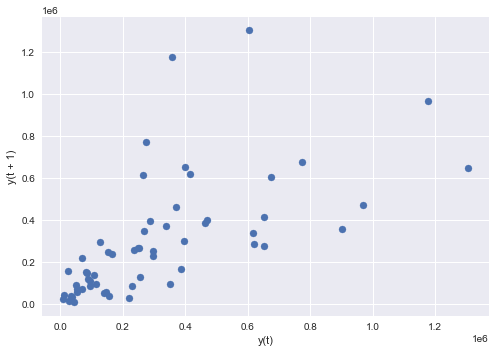

In [8]:
lag_plot(train_df.sellin[train_df.sku_name=="ABEAHAMASHL"])

In [9]:
values = pd.DataFrame(train_df[train_df.sku_name=="ABEAHAMASHL"].sellin.values)
dataframe = pd.concat([values.shift(2), values.shift(1), values], axis=1)
dataframe.columns = ['t-2', 't-1', 't']
result = dataframe.corr()
print(result)

          t-2       t-1         t
t-2  1.000000  0.638911  0.637409
t-1  0.638911  1.000000  0.644704
t    0.637409  0.644704  1.000000


<AxesSubplot:xlabel='Lag', ylabel='Autocorrelation'>

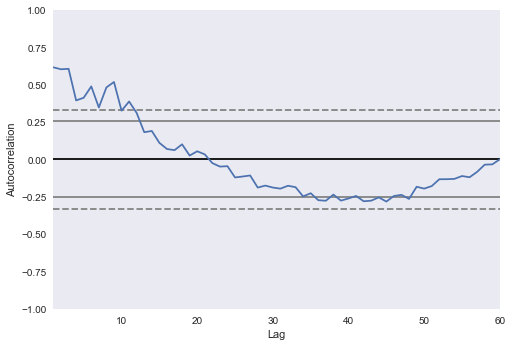

In [10]:
autocorrelation_plot(train_df.sellin[train_df.sku_name=="ABEAHAMASHL"])

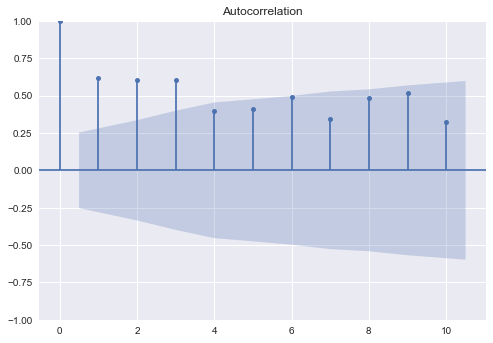

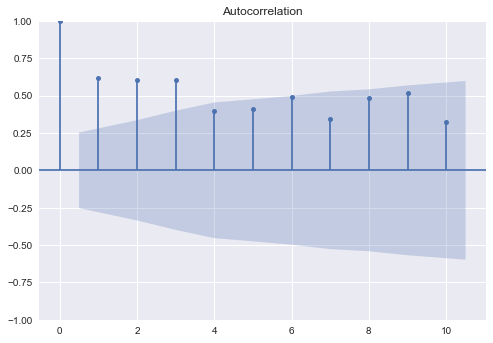

In [11]:
plot_acf(train_df.sellin[train_df.sku_name=="ABEAHAMASHL"], lags=10)

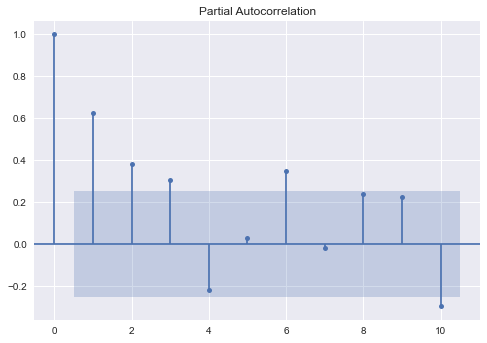

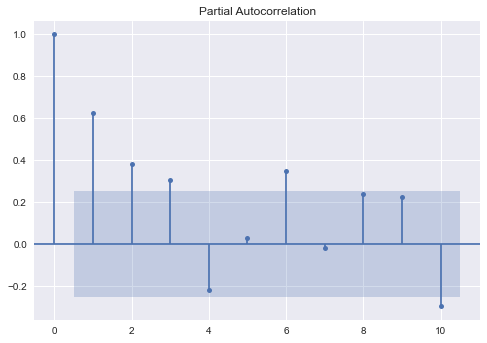

In [11]:
plot_pacf(train_df.sellin[train_df.sku_name=="ABEAHAMASHL"], lags=10)

In [12]:
df=pd.concat([train_df.sellin[train_df.CAT_GENDER_MEN==1].reset_index(drop=True), train_df.sellin[train_df.CAT_GENDER_BOTH==1].reset_index(drop=True), train_df.sellin[train_df.CAT_GENDER_WOMEN==1].reset_index(drop=True)],axis=1)
df.columns=["sellin_M","sellin_B","sellin_W"]
df.corr()

,sellin_M,sellin_B,sellin_W
sellin_M,1.000000,-0.018586,0.003891
sellin_B,-0.018586,1.000000,-0.027866
sellin_W,0.003891,-0.027866,1.000000


<AxesSubplot:xlabel='Lag', ylabel='Autocorrelation'>

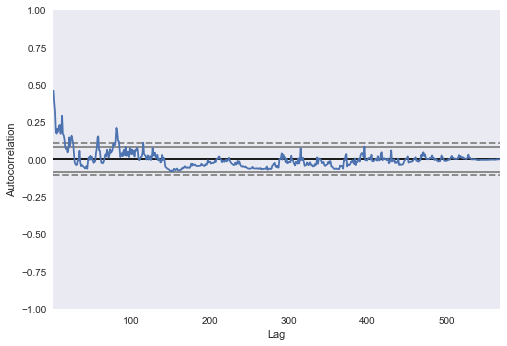

In [13]:
# plot_acf(train_df.sellin[train_df.CAT_GENDER_BOTH==1])
# lag_plot(train_df.sellin[train_df.CAT_GENDER_WOMEN==1])
autocorrelation_plot(train_df.sellin[train_df.CAT_GENDER_BOTH==1])


In [14]:
df_Both=train_df[train_df.CAT_GENDER_BOTH==1]
df_Men=train_df[train_df.CAT_GENDER_MEN==1]
df_Women=train_df[train_df.CAT_GENDER_WOMEN==1]
print(df_Men.sku_name.unique().shape)
print(df_Women.sku_name.unique().shape)
print(df_Both.sku_name.unique().shape)

(1625,)
(2007,)
(236,)


In [15]:
content=[]
for sku in df_Both.sku_name.unique():
    content.append(pd.DataFrame(df_Both.sellin[df_Both.sku_name==sku]).reset_index(drop=True))

df=pd.concat(content, axis=1)
df.columns=df_Both.sku_name.unique()

corr=df.corr()

In [16]:
print(set(df_Men.sku_name.unique()).intersection(df_Both.sku_name.unique()))
print(set(df_Men.sku_name.unique()).intersection(df_Women.sku_name.unique()))
print(set(df_Both.sku_name.unique()).intersection(df_Women.sku_name.unique()))

set()
set()
set()


# **D**ata **P**reprocessing

In [17]:
# cpt=0
# final_train_df=pd.DataFrame(columns= train_df.sku_name.unique(), index=sorted(train_df.date.unique()))
# for date in sorted(train_df.date.unique()):
#     for sku in train_df.sku_name.unique():
#         try:
#             # if train_df.sellin[(train_df.date==date) & (train_df.sku_name==sku)].values.shape[0]>1:
#             #     cpt+=1

#             final_train_df.loc[date,sku]=train_df.sellin[(train_df.date==date) & (train_df.sku_name==sku)].values.sum()
#         except:
#             1
# # print(cpt)

# final_train_df.to_csv("final_train_df.csv", index=False)

In [61]:
cpt=0
final_train_df=pd.DataFrame(columns= train_df.sku_name.unique()[0:50], index=sorted(train_df.date.unique()))
for sku in train_df.sku_name.unique():
    for date in sorted(train_df.date.unique()):
        try:
            # if train_df.sellin[(train_df.date==date) & (train_df.sku_name==sku)].values.shape[0]>1:
            #     cpt+=1

            final_train_df.loc[date,sku]=train_df.sellin[(train_df.date==date) & (train_df.sku_name==sku)].values.max()
        except:
            1
    cpt+=1
    if cpt>=50:
        break

final_train_df.to_csv("final_train_df.csv", index=False)

In [62]:
final_train_df = pd.read_csv("final_train_df.csv")
final_train_df.index = sorted(train_df.date.unique())
final_train_df.head(2)

,YOSHWARDTERR,YOSHUANEMARX,YOSHUANEBART,YOSHTLYNYOSHZZ,YOSHTLYNYOSH,YOSHTLEYMICH,YOSHRTIEROSE,YOSHRTHATRAN,YOSHROBKARR,YOSHRICKLAZA,YOSHRENECARL,YOSHOVANTERR,YOSHOLPHCOLL,YOSHNDAYLEAT,YOSHLROYARTI,YOSHLONAWHITZZ,YOSHLONAWHIT,YOSHLONAVICT,YOSHLONALILL,YOSHLIZAARVI,YOSHLIZAARMA,YOSHLIAMROSE,YOSHLEENILSEZZ,YOSHLEENILSE,YOSHLEENBART,YOSHLEENARMA,YOSHLANDONEI,YOSHLANDJULIZZ,YOSHLANDJULI,YOSHILSEHOWAZZ,YOSHILSEHOWA,YOSHHORALYNE,YOSHHEBAAMBE,YOSHHANGILSE,YOSHHANGARVI,YOSHHAELVICT,YOSHERRYISAA,YOSHENNYAURE,YOSHENNEJULI,YOSHELLYCATH,YOSHELIACORE,YOSHATHAKEVA,YOSHANNABART,WHITZAROSIGR,WHITVETASHER,WHITTLEYSIGR,WHITSHIAALBEZZ,WHITSHIAALBE,WHITSAACREY,WHITRRIEABE
2016-01-01,NaN,NaN,NaN,NaN,32416.0,NaN,NaN,346446.0,NaN,NaN,NaN,1013.0,NaN,NaN,1113287.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16208.0,NaN,NaN,102313.0,NaN,NaN,NaN,1013.0,NaN,1013.0,1732230.0,NaN,NaN,12156.0,NaN,NaN,NaN,8104.0,NaN,NaN,5065.0,NaN,81040.0,100287.0,NaN
2016-02-01,NaN,NaN,NaN,NaN,28364.0,NaN,NaN,23299.0,NaN,NaN,NaN,NaN,1013.0,NaN,434577.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22286.0,NaN,NaN,7091.0,NaN,NaN,NaN,NaN,NaN,NaN,1418200.0,NaN,NaN,68884.0,NaN,NaN,NaN,1013.0,NaN,NaN,NaN,NaN,36468.0,40520.0,NaN


In [63]:
Product=final_train_df[(final_train_df.isna().sum()/final_train_df.shape[0]).sort_values().index[:3]]
Product.fillna(method="bfill", inplace=True)
Product.reset_index(inplace=True)
Product.to_csv("Sellin_Product.csv",index=False)
Product.head(2)

,index,YOSHHAELVICT,YOSHELLYCATH,YOSHLROYARTI
0,2016-01-01,1732230.0,12156.0,1113287.0
1,2016-02-01,1418200.0,12156.0,434577.0


In [18]:
final_train_df = pd.read_csv("final_train_df.csv")
final_train_df.index = sorted(train_df.date.unique())
final_train_df.head(2)

,YOSHWARDTERR,YOSHUANEMARX,YOSHUANEBART,YOSHTLYNYOSHZZ,YOSHTLYNYOSH,YOSHTLEYMICH,YOSHRTIEROSE,YOSHRTHATRAN,YOSHROBKARR,YOSHRICKLAZA,YOSHRENECARL,YOSHOVANTERR,YOSHOLPHCOLL,YOSHNDAYLEAT,YOSHLROYARTI,YOSHLONAWHITZZ,YOSHLONAWHIT,YOSHLONAVICT,YOSHLONALILL,YOSHLIZAARVI,YOSHLIZAARMA,YOSHLIAMROSE,YOSHLEENILSEZZ,YOSHLEENILSE,YOSHLEENBART,YOSHLEENARMA,YOSHLANDONEI,YOSHLANDJULIZZ,YOSHLANDJULI,YOSHILSEHOWAZZ,YOSHILSEHOWA,YOSHHORALYNE,YOSHHEBAAMBE,YOSHHANGILSE,YOSHHANGARVI,YOSHHAELVICT,YOSHERRYISAA,YOSHENNYAURE,YOSHENNEJULI,YOSHELLYCATH,...,ALBEERRYRIGO,ALBEERINLILL,ALBEELLYROSE,ALBECHELGRAH,ALBEATHAPENNZZ,ALBEARTRUDO,ALBEANDAONEI,ABEZARODONO,ABEXIMOHAL,ABEWARDREYZZ,ABEWARDREY,ABEUREAREY,ABETLEYERIC,ABERTHAKEVAZZ,ABERTHAKEVA,ABEROBKRIS,ABERENEELLY,ABENDAYROB,ABENARDONEI,ABEMULAASHL,ABEMONDKRIS,ABEMARXPAMU,ABELROYDONA,ABELIANHARL,ABEJENELEAT,ABEJENECOLL,ABEIBALARTI,ABEHLIEGILD,ABEETTEMICH,ABEETTEABE,ABEERINISAA,ABEENNEBRIT,ABEENNEARMAZZ,ABEELIARUTH,ABECHELLAVE,ABEANNAONEIZZ,ABEANNAONEI,ABEANHARLE,ABEANDACORE,ABEAHAMASHL
2016-01-01,0,0,0,0,32416,0,0,346446,0,0,0,1013,0,0,1113287,0,0,0,0,0,0,0,0,0,0,16208,0,0,102313,0,0,0,1013,0,1013,1732230,0,0,12156,0,...,1013,0,0,0,0,0,0,1013,380888,0,27351,0,0,0,1013,0,0,1013,0,0,0,0,0,0,0,0,0,29377,0,0,0,27351,0,0,1013,0,0,388992,0,902583
2016-02-01,0,0,0,0,28364,0,0,23299,0,0,0,0,1013,0,434577,0,0,0,0,0,0,0,0,0,0,22286,0,0,7091,0,0,0,0,0,0,1418200,0,0,68884,0,...,3039,0,0,0,0,0,0,0,274523,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,29377,0,0,0,7091,0,6078,0,0,0,154989,0,358602


In [19]:
final_train_df.shape

(58, 3868)

In [20]:
final_train_df.to_numpy()

array([[      0,       0,       0, ...,  388992,       0,  902583],
       [      0,       0,       0, ...,  154989,       0,  358602],
       [      0,       0,       0, ...,   39507,       0, 1177106],
       ...,
       [      0,       0,       0, ...,       0,       0,   38494],
       [      0,       0,       0, ...,       0,       0,   29377],
       [      0,       0,       0, ...,       0,       0,   18234]],
      dtype=int64)

# **M**odeling

# ***Make Submission***

In [21]:
test_df=pd.read_csv("Test.csv")

In [22]:
test_df["date"]=test_df["month"].map(str)+"-"+test_df["year"].map(str)
#test_df.date=pd.to_datetime(test_df.date, format='%m-%Y')

In [23]:
test_df.date.unique()

array(['11-2021', '12-2021', '1-2022', '2-2022'], dtype=object)

In [24]:
test_df.sku_name.unique().shape

(382,)

In [25]:
a=set(train_df.sku_name.unique()).intersection(test_df.sku_name.unique())
len(a)

381

In [26]:
set(test_df.sku_name.unique()).difference(a)

{'CATHHALREYZZ'}